In [2]:
pip install copernicusmarine

  Using cached copernicusmarine-2.5.1-py3-none-any.whl.metadata (8.5 kB)
  Using cached arcosparse-0.5.1-py3-none-any.whl.metadata (7.7 kB)
  Using cached boto3-1.43.126-py3-none-any.whl.metadata (6.6 kB)
  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
  Using cached dask-2026.8.0-py3-none-any.whl.metadata (3.8 kB)
  Using cached h5netcdf-1.8.2-py3-none-any.whl.metadata (15 kB)
  Using cached pydantic-2.14.3-py3-none-any.whl.metadata (141 kB)
  Using cached pystac-1.16.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached xarray-2026.9.0-py3-none-any.whl.metadata (12 kB)
  Using cached zarr-3.4.2-py3-none-any.whl.metadata (5.8 kB)
  Using cached pyarrow-26.0.1-cp314-cp314-macosx_12_0_x86_64.whl.metadata (3.0 kB)
  Using cached h5py-3.16.0-cp314-cp314-macosx_10_15_x86_64.whl.metadata (3.0 kB)
  Using cached annotated_types-0.8.0-py3-none-any.whl.metadata (15 kB)
  Using cached pystac_core-1.16.0-py3-none-any.whl.metadata (1.3 kB)
  Using cached pystac_ext_classification-2.0.

In [1]:
# import the modules
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import netCDF4 as nc4
import cartopy.crs as ccrs
import cartopy.feature
from datetime import datetime
import copernicusmarine
import moviepy.video.io.ImageSequenceClip

# define a directory for this homework
lab_directory = "/Volumes/Ant's_HD/Fall 2026 Remote Sensing/Homework 11"

# define folders for the data and figures
data_directory = os.path.join(lab_directory, 'CHLA_Data')
output_dir = os.path.join(lab_directory, 'CHLA_Panels')

# make the folders
os.makedirs(data_directory, exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

print('Data directory:', data_directory)
print('Figure directory:', output_dir)

Data directory: /Volumes/Ant's_HD/Fall 2026 Remote Sensing/Homework 11/CHLA_Data
Figure directory: /Volumes/Ant's_HD/Fall 2026 Remote Sensing/Homework 11/CHLA_Panels


In [2]:
# define the Copernicus Marine dataset
dataset_id = 'cmems_mod_glo_bgc-pft_anfc_0.25deg_P1D-m'

# define the study period
start_date = '2025-11-06'
end_date = '2026-11-06'

# define the Monterey Bay region
min_lat = 35.5
max_lat = 38.0
min_lon = -123.5
max_lon = -121.0

# define the output file
data_file = os.path.join(data_directory, 'Monterey_Bay_CHLA_2025_2026.nc')

# download the chlorophyll-a data
if not os.path.exists(data_file):

    copernicusmarine.subset(
        dataset_id=dataset_id,
        variables=['chl'],
        start_datetime=start_date,
        end_datetime=end_date,
        minimum_longitude=min_lon,
        maximum_longitude=max_lon,
        minimum_latitude=min_lat,
        maximum_latitude=max_lat,
        minimum_depth=0,
        maximum_depth=1,
        output_directory=data_directory,
        output_filename='Monterey_Bay_CHLA_2025_2026.nc'
    )

print('Data file:', data_file)

INFO - 2026-11-08T03:10:59Z - Selected dataset version: "202311"
INFO - 2026-11-08T03:10:59Z - Selected dataset part: "default"
WARNING - 2026-11-08T03:10:59Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.4940253794193268, 5727.91650390625]
INFO - 2026-11-08T03:11:05Z - Total size of the download: 189.44 KB.


Data file: /Volumes/Ant's_HD/Fall 2026 Remote Sensing/Homework 11/CHLA_Data/Monterey_Bay_CHLA_2025_2026.nc


In [3]:
# open the NetCDF file
ds = nc4.Dataset(data_file)

print(ds.variables.keys())

# read the coordinates
longitude = np.array(ds.variables['longitude'][:])
latitude = np.array(ds.variables['latitude'][:])

# read the surface chlorophyll-a
CHLA = np.ma.filled(ds.variables['chl'][:, 0, :, :], np.nan)

# read the dates
time = ds.variables['time']

dates = nc4.num2date(time[:], time.units, calendar=getattr(time, 'calendar', 'standard'))

# convert to Python datetime objects
dates = [datetime(d.year, d.month, d.day,
                  d.hour, d.minute, d.second) for d in dates]

ds.close()

# check the data
print('CHLA shape:', CHLA.shape)
print('First date:', dates[0])
print('Last date:', dates[-1])
print('Minimum CHLA:', np.nanmin(CHLA))
print('Maximum CHLA:', np.nanmax(CHLA))

dict_keys(['depth', 'latitude', 'longitude', 'time', 'chl'])
CHLA shape: (366, 11, 11)
First date: 2025-11-06 00:00:00
Last date: 2026-11-06 00:00:00
Minimum CHLA: 0.08853337
Maximum CHLA: 5.9063873


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


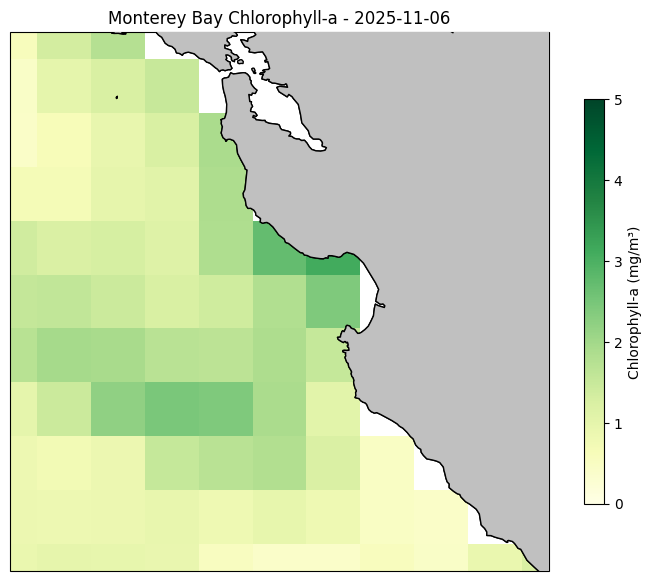

In [4]:
# create the figure
fig = plt.figure(figsize=(9, 7))

ax = plt.axes(projection=ccrs.PlateCarree())

# plot chlorophyll-a
C = plt.pcolormesh(longitude, latitude, CHLA[0, :, :],
                   transform=ccrs.PlateCarree(),
                   vmin=0, vmax=5, cmap='YlGn',
                   shading='auto')

# add the colorbar
cbar = plt.colorbar(C, shrink=0.75)
cbar.set_label('Chlorophyll-a (mg/m³)')

# add land
ax.add_feature(cartopy.feature.LAND,
               facecolor='silver', edgecolor='black',
               zorder=10)

ax.coastlines()

# set the Monterey Bay map extent
ax.set_extent([-123.5, -121.0, 35.5, 38.0])

plt.title('Monterey Bay Chlorophyll-a - ' + str(dates[0])[:10])

plt.show()

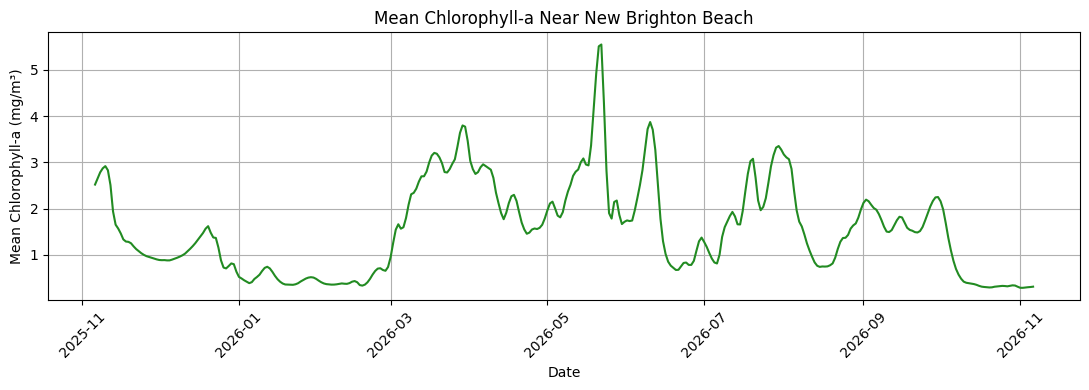

In [5]:
# define the study region
study_min_lon = -122.30
study_max_lon = -121.70
study_min_lat = 36.70
study_max_lat = 37.20

# find the longitude and latitude indices
lon_index = np.where((longitude >= study_min_lon) &
                     (longitude <= study_max_lon))[0]

lat_index = np.where((latitude >= study_min_lat) &
                     (latitude <= study_max_lat))[0]

# calculate mean chlorophyll-a for each date
chla_values = []

for i in range(len(dates)):

    region = CHLA[i, :, :][np.ix_(lat_index, lon_index)]

    if np.isfinite(region).any():
        mean_chla = np.nanmean(region)
    else:
        mean_chla = np.nan

    chla_values.append(mean_chla)

# convert to an array
chla_values = np.array(chla_values)

# plot the time series
plt.figure(figsize=(11, 4))

plt.plot(dates, chla_values, color='forestgreen')

plt.xlabel('Date')
plt.ylabel('Mean Chlorophyll-a (mg/m³)')
plt.title('Mean Chlorophyll-a Near New Brighton Beach')

plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()

# save the figure
figure_file = os.path.join(lab_directory,'McGinnis_Monterey_Bay_CHLA_Timeseries.png')

plt.savefig(figure_file, dpi=300, bbox_inches='tight')
plt.show()

In [6]:
# create a function to make each movie panel
def create_panel(input_index, output_file, save_as_image=True):

    # make the figure
    fig = plt.figure(figsize=(10, 9))

    # first subplot: Monterey Bay chlorophyll-a map
    ax = plt.subplot(2, 1, 1,
                     projection=ccrs.PlateCarree())

    C = ax.pcolormesh(longitude, latitude,
                      CHLA[input_index, :, :],
                      transform=ccrs.PlateCarree(),
                      vmin=0, vmax=5, cmap='YlGn',
                      shading='auto')

    # add land and coastlines
    ax.add_feature(cartopy.feature.LAND,
                   facecolor='silver', edgecolor='black',
                   zorder=10)

    ax.coastlines()

    ax.set_extent([-123.5, -121.0, 35.5, 38.0])

    # show the study region as a black box
    box_lon = [study_min_lon, study_max_lon,
               study_max_lon, study_min_lon, study_min_lon]

    box_lat = [study_min_lat, study_min_lat,
               study_max_lat, study_max_lat, study_min_lat]

    ax.plot(box_lon, box_lat, color='black',
            linewidth=2, transform=ccrs.PlateCarree())

    # add the colorbar
    cbar = plt.colorbar(C, ax=ax, shrink=0.75)
    cbar.set_label('Chlorophyll-a (mg/m³)')

    # add the date
    date_str = str(dates[input_index])[:10]
    ax.set_title('Monterey Bay Chlorophyll-a - ' + date_str)

    # second subplot: chlorophyll-a time series
    ax2 = plt.subplot(2, 1, 2)

    ax2.plot(dates, chla_values,
             color='forestgreen', linewidth=1.5)

    # add the moving marker
    ax2.plot(dates[input_index],
             chla_values[input_index],
             'ro', markersize=9)

    # add a vertical line showing the current date
    ax2.axvline(dates[input_index],
                color='red', linestyle='--')

    ax2.set_xlim(dates[0], dates[-1])
    ax2.set_xlabel('Date')
    ax2.set_ylabel('Mean Chlorophyll-a (mg/m³)')
    ax2.set_title('Mean Chlorophyll-a Near New Brighton Beach')

    ax2.tick_params(axis='x', rotation=45)
    ax2.grid()

    plt.tight_layout()

    # save or display the panel
    if save_as_image:
        plt.savefig(output_file, dpi=120)
        plt.close(fig)
    else:
        plt.show()

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


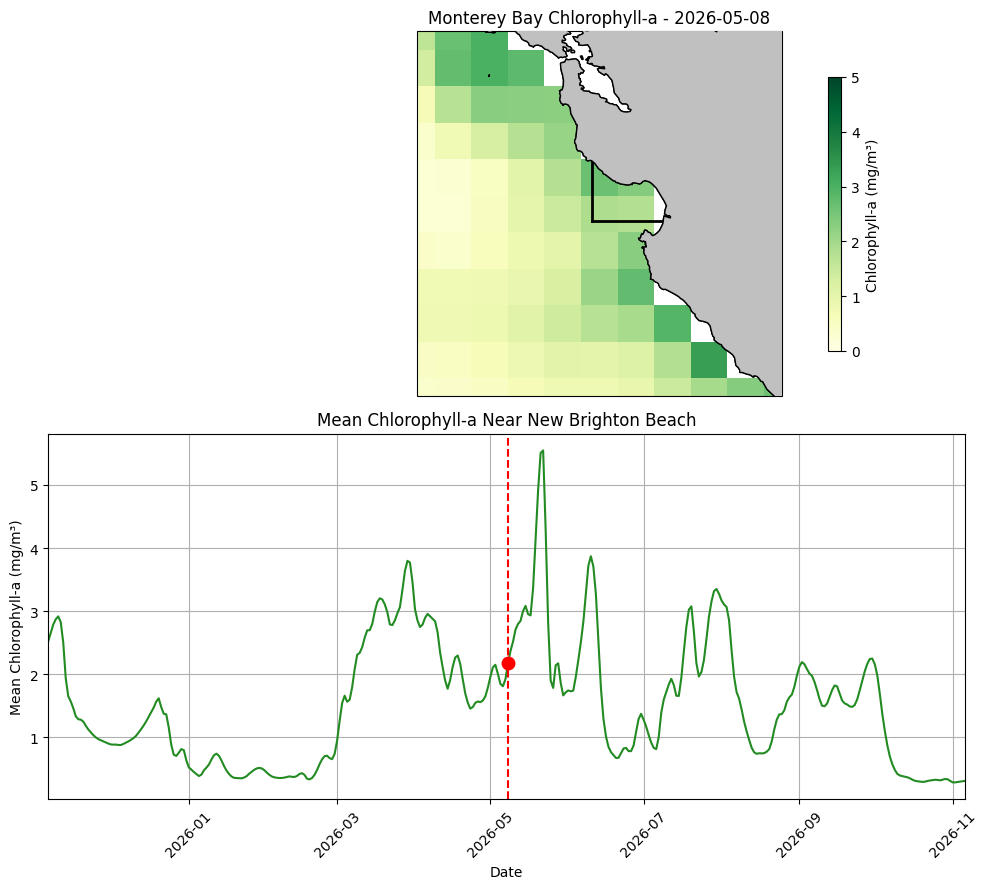

In [7]:
# define the test output file
output_file = os.path.join(output_dir, 'CHLA_test.png')

# display a frame from the middle of the year
create_panel(len(dates)//2, output_file, save_as_image=False)

In [8]:
# make an empty list for the images
image_list = []

# loop through each observation
for i in range(len(dates)):

    output_file = os.path.join(
        output_dir,
        'CHLA_' + str(i).zfill(3) + '.png')

    # create each panel
    create_panel(i, output_file, save_as_image=True)

    image_list.append(output_file)

print('Number of frames:', len(image_list))

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Library/Frameworks/Pyth

Number of frames: 366


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


In [9]:
# create the movie
clip = moviepy.video.io.ImageSequenceClip.ImageSequenceClip(image_list, fps=5)

# define the movie file
movie_file = os.path.join(lab_directory, 'McGinnis_Monterey_Bay_CHLA_Movie.mp4')

# save the movie
clip.write_videofile(movie_file,codec='libx264',audio=False)

clip.close()

print('Movie saved to:', movie_file)

MoviePy - Building video /Volumes/Ant's_HD/Fall 2026 Remote Sensing/Homework 11/McGinnis_Monterey_Bay_CHLA_Movie.mp4.
MoviePy - Writing video /Volumes/Ant's_HD/Fall 2026 Remote Sensing/Homework 11/McGinnis_Monterey_Bay_CHLA_Movie.mp4



MoviePy - Done !
MoviePy - video ready /Volumes/Ant's_HD/Fall 2026 Remote Sensing/Homework 11/McGinnis_Monterey_Bay_CHLA_Movie.mp4
Movie saved to: /Volumes/Ant's_HD/Fall 2026 Remote Sensing/Homework 11/McGinnis_Monterey_Bay_CHLA_Movie.mp4
